## Model 1: DBQA for Ce$^{3+}$:YAG ($4f^1$)

Ce$^{3+}$ substitutes Y$^{3+}$ at a site of $D_2$ symmetry in Y$_3$Al$_5$O$_{12}$. The $4f^1$ configuration has 14 states, embedded in 16 dimensions (4 qubits).
Spin-orbit and crystal-field parameters are from Table 10 of L. Hu, M. F. Reid, C. K. Duan, S. Xia and M. Yin, J. Phys.: Condens. Matter **23**, 045501 (2011), using one complete parameter set in their axis convention.
Crystal-field and spin-orbit effects are of comparable size, so this is a compact benchmark without strong scale separation.

**Question:** how quickly does DBQA recover the low-energy spectrum? The answer sets the energy and fidelity tolerances used for the larger models.

This notebook runs DBQA on the matrix (exact double-bracket rotations). `Example_3_compiled_DBQA_Ce_YAG.ipynb` compiles the circuits and counts gates.

In [1]:
import os
import logging
import pickle

import numpy as np
import matplotlib.pyplot as plt

from qibo import set_backend
from qibo.config import log

from pycf import cfl
from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

# PyCF source tree with the bundled matrix-element bases (examples/*/matel)
os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))

set_backend("numpy")
log.setLevel(logging.ERROR)

[Qibo 0.2.14|INFO|2026-10-15 07:49:11]: Using numpy backend on /CPU:0


In [2]:
def visualize_matrix(matrix, title=""):
    """Visualize hamiltonian in a heatmap form."""
    fig, ax = plt.subplots(figsize=(5,5))
    ax.set_title(title)
    im = ax.imshow(np.absolute(matrix), cmap="inferno")
    fig.colorbar(im, ax=ax)

def plot_histories(histories, labels, key, ylabel, logy=True, filename=None):
    """Plot a recorded quantity over the DBQA iterations."""
    colors = plt.cm.inferno(np.linspace(0.1, 0.8, len(histories)))
    plt.figure(figsize=(5,5*6/8))
    for i, (h, l) in enumerate(zip(histories, labels)):
        plt.plot([r[key] for r in h], lw=2, color=colors[i], label=l, marker='.')
    if logy:
        plt.yscale("log")
    plt.legend()
    plt.xlabel("Iterations")
    plt.ylabel(ylabel)
    plt.grid(True)
    if filename is not None:
        plt.savefig(f"pdfs_figures/{filename}.pdf", bbox_inches="tight")
    plt.show()

#### The crystal-field Hamiltonian

Hu *et al.* list two complete $4f$ parameter sets in the same axis convention: column [a], the fit of Tanner *et al.* (2007) rotated by $\pi/2$ about $z$ to their axes (`"fitted"`), and column [c], their DV-X$\alpha$ calculation (`"calculated"`). We use the fitted set and repeat the benchmark with the calculated set at the end.
For a $D_2$ site all $B^k_q$ are real and only even $q$ appear.

Note: the calculated set does not reproduce the calculated $4f$ levels that Hu *et al.* list in their Table 9 (differences up to 760 cm$^{-1}$). The normalisation check in `Example_1` and the tests rule out a convention mismatch on our side, so the most likely cause is the truncation of their effective Hamiltonian to $\zeta$ and the nine $B^k_q$. This does not affect the benchmark, whose reference is always the exact spectrum of the Hamiltonian that is fed to DBQA.

In [3]:
parameter_set = "fitted"
coeff = dict(CE_YAG_HU2011[parameter_set], EAVG=0.0)
for name, value in coeff.items():
    print(f"{name:5s} {value:8.1f} cm^-1")

ZETA     647.0 cm^-1
C20     -465.0 cm^-1
C22       96.0 cm^-1
C40    -3739.0 cm^-1
C42      380.0 cm^-1
C44     1602.0 cm^-1
C60      901.0 cm^-1
C62     -307.0 cm^-1
C64     2136.0 cm^-1
C66     -246.0 cm^-1
EAVG       0.0 cm^-1


nqubits = 4, physical states = 14


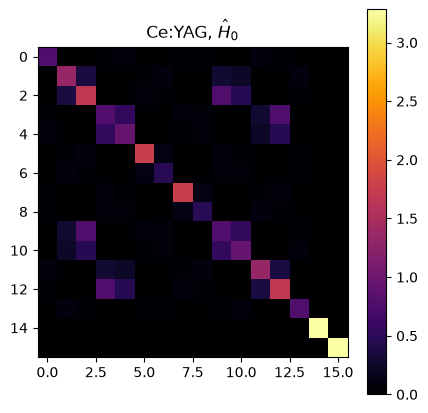

In [4]:
f1cf = ImportSLJM(pycf_matel_path("f1cf", "ceylf"))
tensors = [f1cf.EAVG] + [getattr(f1cf, name) for name in CE_YAG_TENSORS]

energy_unit = 1000.0
h, n_physical = crystal_field_hamiltonian(tensors, coeff, energy_unit=energy_unit)
h_matrix = h.backend.to_numpy(h.matrix)
energies, vectors = np.linalg.eigh(h_matrix)
tol = 1e-5  # in energy_unit, i.e. 0.01 cm^-1
max_inside, min_between = check_grouping_tolerance(energies, tol)
assert max_inside < tol < min_between
groups = group_levels(energies, tol)
os.makedirs("pdfs_figures", exist_ok=True)
os.makedirs("simulation_results", exist_ok=True)
print(f"nqubits = {h.nqubits}, physical states = {n_physical}")
visualize_matrix(h_matrix, title=r"Ce:YAG, $\hat H_0$")

#### Exact spectrum and level grouping

The exact spectrum of the embedded Hamiltonian is the reference for every DBQA iterate. All levels are Kramers doublets: three from $^2F_{5/2}$ (the low-energy spectrum) and four from $^2F_{7/2}$, plus the two padding states.
The grouping tolerance (0.01 cm$^{-1}$) was fixed above, before any DBQA run, from the exact spectrum: it is larger than the largest splitting inside a level and smaller than the smallest gap between levels.

In [5]:
print(f"largest splitting inside a level: {energy_unit*max_inside:.2e} cm^-1, smallest gap between levels: {energy_unit*min_between:.1f} cm^-1")
for k, g in enumerate(groups):
    kind = "padding" if g[0] >= n_physical else ("2F5/2" if k < 3 else "2F7/2")
    print(f"level {k}: {energy_unit*(energies[g[0]] - energies[0]):8.1f} cm^-1, d = {len(g)}  {kind}")

largest splitting inside a level: 3.11e-12 cm^-1, smallest gap between levels: 94.0 cm^-1
level 0:      0.0 cm^-1, d = 2  2F5/2
level 1:    321.9 cm^-1, d = 2  2F5/2
level 2:    733.7 cm^-1, d = 2  2F5/2
level 3:   2250.4 cm^-1, d = 2  2F7/2
level 4:   2492.8 cm^-1, d = 2  2F7/2
level 5:   2586.8 cm^-1, d = 2  2F7/2
level 6:   4046.9 cm^-1, d = 2  2F7/2
level 7:   5058.6 cm^-1, d = 2  padding


#### DBQA strategies

We compare three double-bracket rotations from `qibo_dbqa`, each with the step $s_k$ chosen by grid search to minimise the off-diagonal norm $\|\sigma(\hat H_k)\|$:
- `canonical`: the GWW bracket $W_k = [\Delta(\hat H_k), \hat H_k]$,
- `single_commutator` with $D_k$ chosen at each step among all products of Pauli $Z$ operators (`select_best_dbr_generator`), the diagonal operators that are simple to implement on qubits,
- `group_commutator`, the product formula $e^{is\hat H_k}e^{is D_k}e^{-is\hat H_k}e^{-isD_k}$ with $D_k=\Delta(\hat H_k)$, which only needs evolutions under $\hat H_k$ and $D_k$.

At every iteration `dbqa_spectrum_report` records the energy error of each level (diagonal of $\hat H_k$ against the exact spectrum), the projector fidelity of each Kramers doublet, the error of each gap between consecutive levels and the off-diagonal norm.

In [6]:
from copy import deepcopy

from qibo_dbqa.double_bracket import (
    DoubleBracketGeneratorType,
    DoubleBracketIteration,
    DoubleBracketScheduling,
)
from qibo_dbqa.utils import generate_Z_operators
from qibo_dbqa.utils_dbr_strategies import select_best_dbr_generator

NSTEPS = 60
space = np.linspace(1e-4, 0.3, 300)
labels = ["canonical", "Pauli-Z", "group commutator"]


def run_dbqa(h, method, groups, energies, nsteps=NSTEPS):
    """Run `nsteps` DBQA iterations with one of the three strategies and record the spectrum report."""
    if method == "canonical":
        dbi = DoubleBracketIteration(deepcopy(h), mode=DoubleBracketGeneratorType.canonical, scheduling=DoubleBracketScheduling.grid_search)
    elif method == "Pauli-Z":
        dbi = DoubleBracketIteration(deepcopy(h), mode=DoubleBracketGeneratorType.single_commutator, scheduling=DoubleBracketScheduling.grid_search)
        Z_ops = list(generate_Z_operators(h.nqubits).values())
    elif method == "group commutator":
        dbi = DoubleBracketIteration(deepcopy(h), mode=DoubleBracketGeneratorType.group_commutator, scheduling=DoubleBracketScheduling.grid_search)
    history, steps = [dbqa_spectrum_report(dbi, groups, energies)], []
    for _ in range(nsteps):
        if method == "canonical":
            step = dbi.choose_step(space=space)
            dbi(step=step)
        elif method == "Pauli-Z":
            dbi, idx, step, flip = select_best_dbr_generator(dbi, Z_ops, compare_canonical=False, space=space)
        elif method == "group commutator":
            step = dbi.choose_step(space=np.linspace(1e-3, 1.0, 300))
            dbi(step=step)
        steps.append(step)
        history.append(dbqa_spectrum_report(dbi, groups, energies))
    for r in history:
        r["ground_multiplet_energy_error"] = energy_unit * np.max(r["level_energy_error"][:3])
        r["ground_multiplet_infidelity"] = 1 - np.min(r["level_fidelity"][:3])
        r["physical_energy_error"] = energy_unit * np.max(r["level_energy_error"][:7])
        r["physical_infidelity"] = 1 - np.min(r["level_fidelity"][:7])
    return dbi, history, steps

#### Method 1: canonical bracket

In [7]:
dbi_canonical, history_canonical, steps_canonical = run_dbqa(h, "canonical", groups, energies)

#### Method 2: Pauli-$Z$ generators

In [8]:
dbi_pauli, history_pauli, steps_pauli = run_dbqa(h, "Pauli-Z", groups, energies)

#### Method 3: group commutator

In [9]:
dbi_group_commutator, history_group_commutator, steps_group_commutator = run_dbqa(h, "group commutator", groups, energies)

#### Convergence

off-diagonal norm reduction after 60 iterations:
  canonical         2.392 -> 1.417e-01  (factor 16.9)
  Pauli-Z           2.392 -> 4.724e-02  (factor 50.6)
  group commutator  2.392 -> 8.253e-02  (factor 29.0)


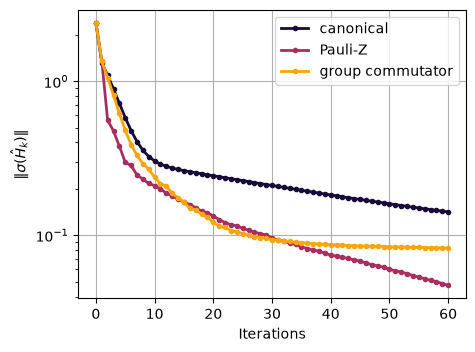

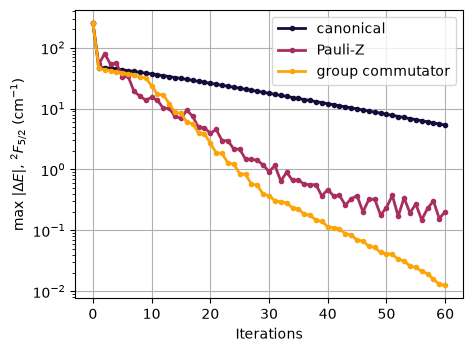

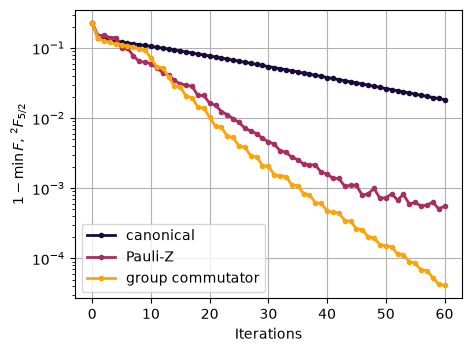

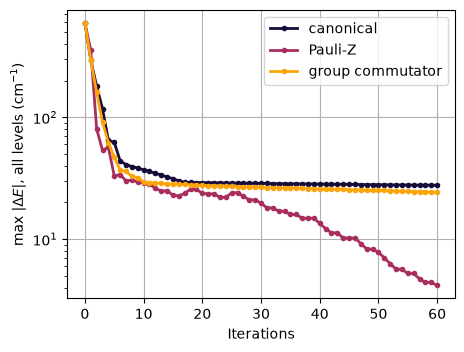

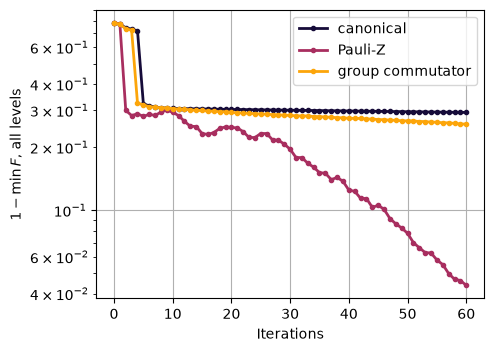

In [10]:
histories = [history_canonical, history_pauli, history_group_commutator]
step_histories = [steps_canonical, steps_pauli, steps_group_commutator]
dbis = [dbi_canonical, dbi_pauli, dbi_group_commutator]

print("off-diagonal norm reduction after", NSTEPS, "iterations:")
for label, history in zip(labels, histories):
    print(f"  {label:17s} {history[0]['off_diagonal_norm']:.3f} -> {history[-1]['off_diagonal_norm']:.3e}  (factor {history[0]['off_diagonal_norm'] / history[-1]['off_diagonal_norm']:.1f})")

plot_histories(histories, labels, "off_diagonal_norm", r"$\| \sigma(\hat{H}_k) \|$", filename="Ce_YAG_off_diagonal_norm")
plot_histories(histories, labels, "ground_multiplet_energy_error", r"max $|\Delta E|$, $^2F_{5/2}$ (cm$^{-1}$)", filename="Ce_YAG_ground_multiplet_energy_error")
plot_histories(histories, labels, "ground_multiplet_infidelity", r"$1-\min F$, $^2F_{5/2}$", filename="Ce_YAG_ground_multiplet_infidelity")
plot_histories(histories, labels, "physical_energy_error", r"max $|\Delta E|$, all levels (cm$^{-1}$)", filename="Ce_YAG_all_levels_energy_error")
plot_histories(histories, labels, "physical_infidelity", r"$1-\min F$, all levels", filename="Ce_YAG_all_levels_infidelity")

#### Iterations to reach a tolerance

We count the DBQA iterations after which the error stays below a threshold, for the ground multiplet $^2F_{5/2}$ and for all seven doublets.

In [11]:
def iterations_to_reach(history, key, threshold):
    values = np.array([r[key] for r in history])
    above = np.nonzero(values > threshold)[0]
    if len(above) == 0:
        return 0
    return above[-1] + 1 if above[-1] + 1 < len(values) else None

thresholds = [
    ("ground_multiplet_energy_error", 10.0), ("ground_multiplet_energy_error", 1.0), ("ground_multiplet_energy_error", 0.1),
    ("ground_multiplet_infidelity", 1e-2), ("ground_multiplet_infidelity", 1e-3), ("ground_multiplet_infidelity", 1e-4),
    ("physical_energy_error", 10.0), ("physical_energy_error", 1.0),
    ("physical_infidelity", 1e-2), ("physical_infidelity", 1e-3),
]

def print_iteration_table(histories):
    print(f"{'quantity':32s} {'threshold':>9s} " + " ".join(f"{l:>17s}" for l in labels))
    for key, threshold in thresholds:
        counts = [iterations_to_reach(history, key, threshold) for history in histories]
        print(f"{key:32s} {threshold:9.0e} " + " ".join(f"{'> %d' % NSTEPS if c is None else c:>17}" for c in counts))

print_iteration_table(histories)

quantity                         threshold         canonical           Pauli-Z  group commutator
ground_multiplet_energy_error        1e+01                45                14                14
ground_multiplet_energy_error        1e+00              > 60                32                25
ground_multiplet_energy_error        1e-01              > 60              > 60                43
ground_multiplet_infidelity          1e-02              > 60                24                21
ground_multiplet_infidelity          1e-03              > 60                46                36
ground_multiplet_infidelity          1e-04              > 60              > 60                54
physical_energy_error                1e+01              > 60                47              > 60
physical_energy_error                1e+00              > 60              > 60              > 60
physical_infidelity                  1e-02              > 60              > 60              > 60
physical_infidelity           

In [12]:
fmt = {'float_kind': lambda x: f'{x:.1e}'}
print(f"Errors after {NSTEPS} iterations:")
for label, history in zip(labels, histories):
    r = history[-1]
    print(f"{label:17s} level |dE| (cm^-1)    = {np.array2string(energy_unit * r['level_energy_error'][:7], formatter=fmt)}")
    print(f"{'':17s} level 1-F             = {np.array2string(1 - r['level_fidelity'][:7], formatter=fmt)}")
    print(f"{'':17s} gap error (cm^-1)     = {np.array2string(energy_unit * r['level_gap_error'][:6], formatter=fmt)}")

Errors after 60 iterations:
canonical         level |dE| (cm^-1)    = [1.7e+00 3.6e+00 5.3e+00 1.5e+00 2.6e+01 2.8e+01 8.9e-03]
                  level 1-F             = [5.4e-03 1.8e-02 1.3e-02 5.0e-03 2.9e-01 2.9e-01 2.2e-06]
                  gap error (cm^-1)     = [1.9e+00 9.0e+00 6.9e+00 2.5e+01 5.4e+01 2.8e+01]
Pauli-Z           level |dE| (cm^-1)    = [1.4e-01 2.0e-01 2.0e-01 4.9e-01 3.7e+00 4.2e+00 5.0e-04]
                  level 1-F             = [2.6e-04 5.5e-04 3.0e-04 1.8e-03 4.4e-02 4.2e-02 1.3e-07]
                  gap error (cm^-1)     = [4.5e-02 1.5e-01 5.4e-01 3.1e+00 7.5e+00 4.0e+00]
group commutator  level |dE| (cm^-1)    = [1.2e-02 1.1e-02 1.2e-03 3.2e-02 2.4e+01 2.4e+01 2.0e-04]
                  level 1-F             = [3.8e-05 4.1e-05 2.9e-06 1.2e-04 2.6e-01 2.6e-01 5.8e-08]
                  gap error (cm^-1)     = [2.3e-02 9.7e-03 3.4e-02 2.4e+01 4.8e+01 2.4e+01]


#### The closest pair of levels

The slowest levels are the $^2F_{7/2}$ doublets 4 and 5, separated by the smallest gap of the spectrum (94 cm$^{-1}$). For such a pair we also report the fidelity of the joint two-level subspace and the gap error $|\Delta E_{\rm DBQA}-\Delta E_{\rm exact}|$, which separate a pair that is isolated from the rest of the spectrum but not yet resolved internally from a pair that is still mixed with other levels.

In [13]:
pair = [4, 5]
groups_pair = [g for k, g in enumerate(groups) if k not in pair] + [groups[pair[0]] + groups[pair[1]]]
for dbi, label, history in zip(dbis, labels, histories):
    report = dbqa_spectrum_report(dbi, groups_pair, energies)
    print(f"{label:17s} individual 1-F = {np.array2string(1 - history[-1]['level_fidelity'][pair], formatter=fmt)},"
          f" pair subspace 1-F = {1 - report['level_fidelity'][-1]:.1e},"
          f" gap error = {energy_unit * history[-1]['level_gap_error'][pair[0]]:.2f} cm^-1")

canonical         individual 1-F = [2.9e-01 2.9e-01], pair subspace 1-F = 2.5e-03, gap error = 53.76 cm^-1
Pauli-Z           individual 1-F = [4.4e-02 4.2e-02], pair subspace 1-F = 8.9e-04, gap error = 7.46 cm^-1
group commutator  individual 1-F = [2.6e-01 2.6e-01], pair subspace 1-F = 6.0e-05, gap error = 48.39 cm^-1


#### From fidelity to energy tolerances

The diagonal entries of $\hat H_k$ are expectation values of $\hat H_0$ in the approximate eigenvectors, so the energy error of a level is second order in the eigenvector error: $|\Delta E| \lesssim (1-F)\,\Delta$, where $\Delta$ is the energy range over which the level is mixed. We check this on all iterates of the ground multiplet, with $\Delta$ the largest distance from the level to any other physical level. This converts a fidelity tolerance into an energy tolerance (and vice versa) for the larger models.

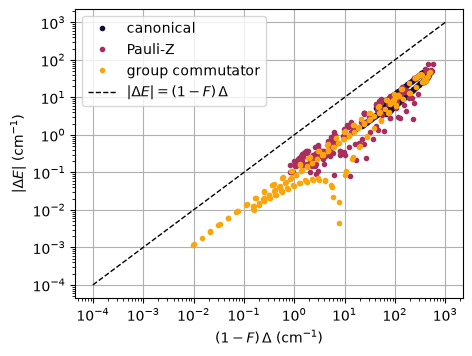

|dE| / ((1-F) Delta): max = 0.222, median = 0.082


In [14]:
level_energies = np.array([np.mean(energies[g]) for g in groups])
ratios = []
plt.figure(figsize=(5,5*6/8))
colors = plt.cm.inferno(np.linspace(0.1, 0.8, len(histories)))
for i, (label, history) in enumerate(zip(labels, histories)):
    x, y = [], []
    for r in history[1:]:
        for k in range(3):
            spread = np.max(np.abs(level_energies[:7] - level_energies[k]))
            x.append((1 - r["level_fidelity"][k]) * spread * energy_unit)
            y.append(r["level_energy_error"][k] * energy_unit)
    ratios += list(np.array(y) / np.array(x))
    plt.loglog(x, y, ".", color=colors[i], label=label)
lim = [1e-4, 1e3]
plt.loglog(lim, lim, "k--", lw=1, label=r"$|\Delta E| = (1-F)\,\Delta$")
plt.xlabel(r"$(1-F)\,\Delta$ (cm$^{-1}$)")
plt.ylabel(r"$|\Delta E|$ (cm$^{-1}$)")
plt.legend(); plt.grid(True)
plt.savefig("pdfs_figures/Ce_YAG_energy_vs_fidelity.pdf", bbox_inches="tight")
plt.show()
print(f"|dE| / ((1-F) Delta): max = {np.max(ratios):.3f}, median = {np.median(ratios):.3f}")

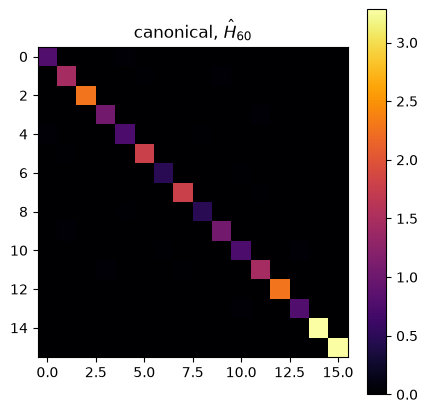

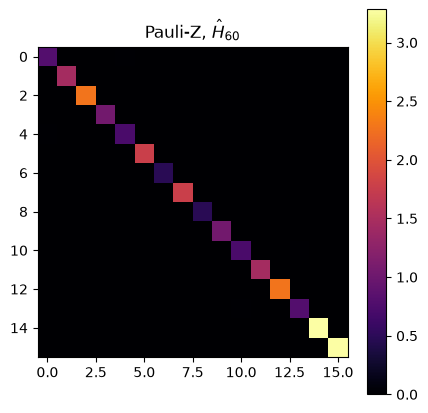

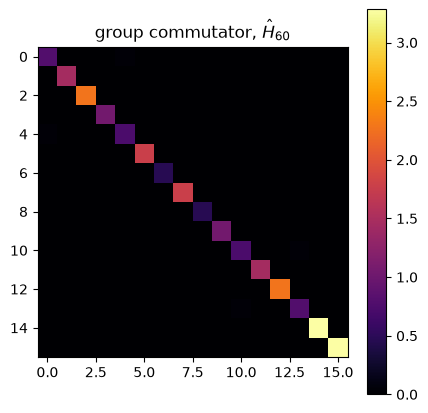

In [15]:
for dbi, label in zip(dbis, labels):
    visualize_matrix(dbi.h.matrix, title=f"{label}, $\\hat H_{{{NSTEPS}}}$")

#### Sensitivity to the parameter set

We repeat the benchmark with the calculated parameter set (column [c] of Hu *et al.*). Its spectrum is different, so the iteration counts show how much the conclusions depend on the particular parameters.

calculated set, levels (cm^-1): [   0.   202.5  577.5 2591.8 2743.6 2961.  3737.1 4671.4]
smallest gap between levels: 151.8 cm^-1


quantity                         threshold         canonical           Pauli-Z  group commutator
ground_multiplet_energy_error        1e+01              > 60                25                20
ground_multiplet_energy_error        1e+00              > 60              > 60                58
ground_multiplet_energy_error        1e-01              > 60              > 60              > 60
ground_multiplet_infidelity          1e-02              > 60                56                44
ground_multiplet_infidelity          1e-03              > 60              > 60              > 60
ground_multiplet_infidelity          1e-04              > 60              > 60              > 60
physical_energy_error                1e+01              > 60                46              > 60
physical_energy_error                1e+00              > 60              > 60              > 60
physical_infidelity                  1e-02              > 60              > 60              > 60
physical_infidelity           

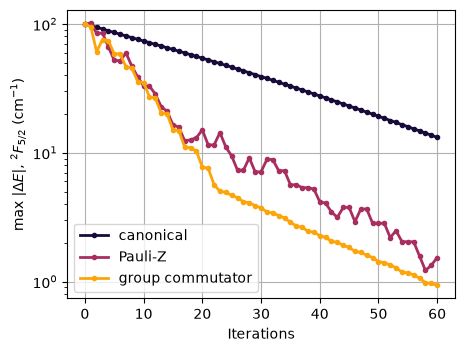

In [16]:
coeff_calculated = dict(CE_YAG_HU2011["calculated"], EAVG=0.0)
h_calculated, _ = crystal_field_hamiltonian(tensors, coeff_calculated, energy_unit=energy_unit)
energies_calculated = np.linalg.eigvalsh(h_calculated.backend.to_numpy(h_calculated.matrix))
max_inside_c, min_between_c = check_grouping_tolerance(energies_calculated, tol)
assert max_inside_c < tol < min_between_c
groups_calculated = group_levels(energies_calculated, tol)
print("calculated set, levels (cm^-1):", np.round(energy_unit * (np.array([energies_calculated[g[0]] for g in groups_calculated]) - energies_calculated[0]), 1))
print(f"smallest gap between levels: {energy_unit*min_between_c:.1f} cm^-1")
histories_calculated = [run_dbqa(h_calculated, method, groups_calculated, energies_calculated)[1] for method in labels]
print_iteration_table(histories_calculated)
plot_histories(histories_calculated, labels, "ground_multiplet_energy_error", r"max $|\Delta E|$, $^2F_{5/2}$ (cm$^{-1}$)", filename="Ce_YAG_calculated_ground_multiplet_energy_error")

#### Saving the data

In [17]:
with open(f"simulation_results/Ce_YAG_DBQA_L_{h.nqubits}.pickle", "wb") as file:
    pickle.dump(
        dict(
            coeff=dict(fitted=coeff, calculated=coeff_calculated),
            energy_unit=energy_unit,
            energies=dict(fitted=energies, calculated=energies_calculated),
            groups=dict(fitted=groups, calculated=groups_calculated),
            labels=labels,
            histories=dict(fitted=histories, calculated=histories_calculated),
            steps=step_histories,
        ),
        file,
    )